# Design of Experiments Notebook


In [1]:
# Install once if needed:
# %pip install pandas matplotlib jinja2

import pandas as pd
from IPython.display import display

from ffd_measurements import (
    BOX_BEHNKEN_NEW_SCALE_MASS_MEASUREMENTS_G,
    BOX_BEHNKEN_NEW_SCALE_RUN_LABELS,
    IRONING_MASS_MEASUREMENTS_G,
    IRONING_RUN_LABELS,
    EXTRA_RUN_MASS_MEASUREMENTS_G,
    EXTRA_RUN_LABELS,
    FD_I_MASS_1_G,
    FD_I_MASS_MEASUREMENTS_G,
    FD_I_REPEAT_MASS_1_G,
    FD_I_REPEAT_MASS_MEASUREMENTS_G,
    FD_II_MASS_MEASUREMENTS_G,
)
from ffd_utils import (
    build_mass_measurements,
    build_repeat_mass_table,
    build_repeat_mass_measurements,
    build_result_matrix,
    build_main_effect_prediction_comparison,
    build_quadratic_anova_table,
    build_single_mass_table,
    style_extra_run_candidates,
    coded_setting_from_effects,
    build_extra_run_candidates,
    create_box_behnken_design,
    create_two_level_factorial_design,
    calculate_center_point_repeatability,
    calculate_repeatability,
    compute_main_effects,
    fit_quadratic_response_surface,
    plot_quadratic_coefficients,
    plot_quadratic_observed_vs_predicted,
    plot_quadratic_pareto,
    plot_quadratic_response_surface_slices,
    plot_quadratic_surface_and_contour_pairs,
    create_fractional_factorial_design,
    map_coded_to_real,
    plot_main_effects_bar,
    plot_main_effects_line,
    plot_main_effects_line_comparison,
    plot_mass_measurements,
    plot_center_point_repeatability,
    plot_repeatability_summary_comparison,
    plot_three_level_main_effects,
    randomized_second_run_order,
    style_low_high,
    add_interactions,
    compute_interaction_effects,
    plot_interaction_effects,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.expand_frame_repr", False)


In [2]:
FD_I_LEVELS = {
    "A_flow_ratio": {-1: 1.00, 1: 1.05},
    "B_nozzle_temp": {-1: 220, 1: 230},
    "C_speed": {-1: 50, 1: 200},
    "D_line_width": {-1: 0.62, 1: 0.75},
    "E_layer_height": {-1: 0.12, 1: 0.18},
    "F_walls": {-1: 4, 1: 10},
}

FD_II_LEVELS = {
    "A_flow_ratio": {-1: 1.00, 1: 1.05},
    "B_nozzle_temp": {-1: 220, 1: 230},
    "C_speed": {-1: 50, 1: 100},
    "D_line_width": {-1: 0.62, 1: 0.75},
    "E_layer_height": {-1: 0.12, 1: 0.18},
}

DISPLAY_NAMES = {
    "A_flow_ratio": "Flow Ratio (-)",
    "B_nozzle_temp": "Nozzle Temp (deg C)",
    "C_speed": "Print Speed (mm/s)",
    "D_line_width": "Line Width (mm)",
    "E_layer_height": "Layer Height (mm)",
    "F_walls": "Walls (-)",
}


## Step 1: Define DoE Run Matrices


### FD_I Screening Matrix With Wall Factors


In [3]:
fd_I_coded_df = create_fractional_factorial_design(include_walls=True)
fd_I_real_df = map_coded_to_real(fd_I_coded_df, FD_I_LEVELS)

fd_I_coded_display = fd_I_coded_df.rename(columns=DISPLAY_NAMES).reset_index()
fd_I_real_display = fd_I_real_df.rename(columns=DISPLAY_NAMES).reset_index()

display(fd_I_coded_display)
#display(fd_I_real_display)


,Run,Flow Ratio (-),Nozzle Temp (deg C),Print Speed (mm/s),Line Width (mm),Layer Height (mm),Walls (-)
0,1,-1,-1,-1,-1,1,1
1,2,-1,-1,-1,1,1,1
2,3,-1,-1,1,-1,1,-1
3,4,-1,-1,1,1,1,-1
4,5,-1,1,-1,-1,-1,1
5,6,-1,1,-1,1,-1,1
6,7,-1,1,1,-1,-1,-1
7,8,-1,1,1,1,-1,-1
8,9,1,-1,-1,-1,-1,-1
9,10,1,-1,-1,1,-1,-1


In [4]:
#style_low_high(fd_I_real_df, FD_I_LEVELS)


In [5]:
rep2 = randomized_second_run_order(random_state=123)
#rep2


### FD_II Screening Matrix Without Wall Factors


In [6]:
fd_II_coded_df = create_fractional_factorial_design(include_walls=False)
fd_II_real_df = map_coded_to_real(fd_II_coded_df, FD_II_LEVELS)

display(fd_II_coded_df)
#display(fd_II_real_df)


,A_flow_ratio,B_nozzle_temp,C_speed,D_line_width,E_layer_height
Run,,,,,
1,-1,-1,-1,-1,1
2,-1,-1,-1,1,1
3,-1,-1,1,-1,1
4,-1,-1,1,1,1
5,-1,1,-1,-1,-1
6,-1,1,-1,1,-1
7,-1,1,1,-1,-1
8,-1,1,1,1,-1
9,1,-1,-1,-1,-1


### Extra Confirmation And Optimization Candidate Runs


#### 2-Factor 3-Level Candidate Matrix


In [7]:
# 2-parameter option: 9 runs.
# This is a full 3 x 3 grid and does not use Box-Behnken.
EXTRA_RUN_NOZZLE_LINE_WIDTH_LEVELS = {
    "B_nozzle_temp": [225, 230, 235],
    "D_line_width": [0.62, 0.70, 0.80],
}

extra_run_9_real = pd.MultiIndex.from_product(
    EXTRA_RUN_NOZZLE_LINE_WIDTH_LEVELS.values(),
    names=EXTRA_RUN_NOZZLE_LINE_WIDTH_LEVELS.keys(),
).to_frame(index=False)
extra_run_9_real.index += 1
extra_run_9_real.index.name = "Run"

display(extra_run_9_real)


,B_nozzle_temp,D_line_width
Run,,
1,225,0.62
2,225,0.70
3,225,0.80
4,230,0.62
5,230,0.70
6,230,0.80
7,235,0.62
8,235,0.70
9,235,0.80


#### 3-Factor Box-Behnken Candidate Matrix


In [8]:
# 3-parameter option: 15 runs.
# Box-Behnken needs exactly 3 factors, so keep layer height included here.
EXTRA_RUN_BOX_BEHNKEN_LEVELS = {
    "B_nozzle_temp": {-1: 225, 0: 230, 1: 235},
    "D_line_width": {-1: 0.62, 0: 0.70, 1: 0.80},
    "E_layer_height": {-1: 0.10, 0: 0.12, 1: 0.14},
}

extra_run_15_coded, extra_run_15_real = create_box_behnken_design(
    EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    center_repeats=3,
)

display(extra_run_15_coded)
display(extra_run_15_real)


,B_nozzle_temp,D_line_width,E_layer_height
Run,,,
1,0,-1,-1
2,0,-1,1
3,0,1,-1
4,0,1,1
5,-1,0,-1
6,-1,0,1
7,1,0,-1
8,1,0,1
9,-1,-1,0


,B_nozzle_temp,D_line_width,E_layer_height
Run,,,
1,230,0.62,0.10
2,230,0.62,0.14
3,230,0.80,0.10
4,230,0.80,0.14
5,225,0.70,0.10
6,225,0.70,0.14
7,235,0.70,0.10
8,235,0.70,0.14
9,225,0.62,0.12


### Ironing Trial Matrix


In [9]:
IRONING_FIXED_SETTINGS = {
    "C_ironing_line_spacing_mm": 0.15,
    "E_layer_height": 0.12,
    "F_line_width_mm": 0.62,
}

IRONING_LEVELS = {
    "A_flow_ratio": {-1: 0.99, 0: 1.00, 1: 1.01},
    "B_nozzle_temp_C": {-1: 215, 0: 220, 1: 225},
    "C_ironing_flow_percent": {-1: 0, 0: 1, 1: 2},
    "D_ironing_speed_mm_s": {-1: 30, 0: 45, 1: 60},
}

# 4-factor half-fraction screening design plus center runs.
# Generator: D = A*B*C, so the defining relation is I = A*B*C*D.
# This gives 8 factorial runs + 3 center repeats = 11 runs total.
# Main effects are not aliased with two-factor interactions, but two-factor
# interactions are aliased in pairs: AB=CD, AC=BD, AD=BC.
ironing_base_factors = [
    "A_flow_ratio",
    "B_nozzle_temp_C",
    "C_ironing_flow_percent",
]
ironing_factorial_coded = pd.MultiIndex.from_product(
    [[-1, 1], [-1, 1], [-1, 1]],
    names=ironing_base_factors,
).to_frame(index=False)
ironing_factorial_coded["D_ironing_speed_mm_s"] = (
    ironing_factorial_coded["A_flow_ratio"]
    * ironing_factorial_coded["B_nozzle_temp_C"]
    * ironing_factorial_coded["C_ironing_flow_percent"]
)
ironing_factorial_coded = ironing_factorial_coded[list(IRONING_LEVELS)]

ironing_center_coded = pd.DataFrame([
    {factor: 0 for factor in IRONING_LEVELS}
    for _ in range(3)
])

ironing_coded = pd.concat(
    [ironing_factorial_coded, ironing_center_coded],
    ignore_index=True,
)
ironing_coded.index += 1
ironing_coded.index.name = "Run"

ironing_real = map_coded_to_real(ironing_coded, IRONING_LEVELS)
for setting, value in IRONING_FIXED_SETTINGS.items():
    ironing_real[setting] = value

print(f"Ironing design runs: {len(ironing_coded)}")
display(ironing_coded)
display(ironing_real)


Ironing design runs: 11


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s
Run,,,,
1,-1,-1,-1,-1
2,-1,-1,1,1
3,-1,1,-1,1
4,-1,1,1,-1
5,1,-1,-1,1
6,1,-1,1,-1
7,1,1,-1,-1
8,1,1,1,1
9,0,0,0,0


,A_flow_ratio,B_nozzle_temp_C,C_ironing_flow_percent,D_ironing_speed_mm_s,C_ironing_line_spacing_mm,E_layer_height,F_line_width_mm
Run,,,,,,,
1,0.99,215,0,30,0.15,0.12,0.62
2,0.99,215,2,60,0.15,0.12,0.62
3,0.99,225,0,60,0.15,0.12,0.62
4,0.99,225,2,30,0.15,0.12,0.62
5,1.01,215,0,60,0.15,0.12,0.62
6,1.01,215,2,30,0.15,0.12,0.62
7,1.01,225,0,30,0.15,0.12,0.62
8,1.01,225,2,60,0.15,0.12,0.62
9,1.00,220,1,45,0.15,0.12,0.62


## Step 2: Enter Measurements And Plot Mass Results


### FD_I Mass Measurements


In [10]:
fd_I_mass_measurements_g, fd_I_mass_columns = build_mass_measurements(
    FD_I_MASS_MEASUREMENTS_G,
    run_prefix="R",
)
fd_I_repeat_mass_measurements_g, fd_I_repeat_mass_columns = build_repeat_mass_measurements(
    FD_I_REPEAT_MASS_MEASUREMENTS_G,
)

display(fd_I_mass_measurements_g[["run", *fd_I_mass_columns, "mass_mean_g", "mass_std_g"]])
display(fd_I_repeat_mass_measurements_g[["run", *fd_I_repeat_mass_columns, "mass_mean_g", "mass_std_g"]])


,run,mass_1_g,mass_mean_g,mass_std_g
0,R1,13.681,13.7,NaN
1,R2,13.657,13.7,NaN
2,R3,13.622,13.6,NaN
3,R4,13.594,13.6,NaN
4,R5,13.796,13.8,NaN
5,R6,13.843,13.8,NaN
6,R7,13.972,14.0,NaN
7,R8,13.973,14.0,NaN
8,R9,14.480,14.5,NaN
9,R10,14.541,14.5,NaN


,run,mass_1_g,mass_mean_g,mass_std_g
0,R2.2,13.795,13.8,NaN
1,R9.2,14.555,14.6,NaN
2,R12.2,14.628,14.6,NaN


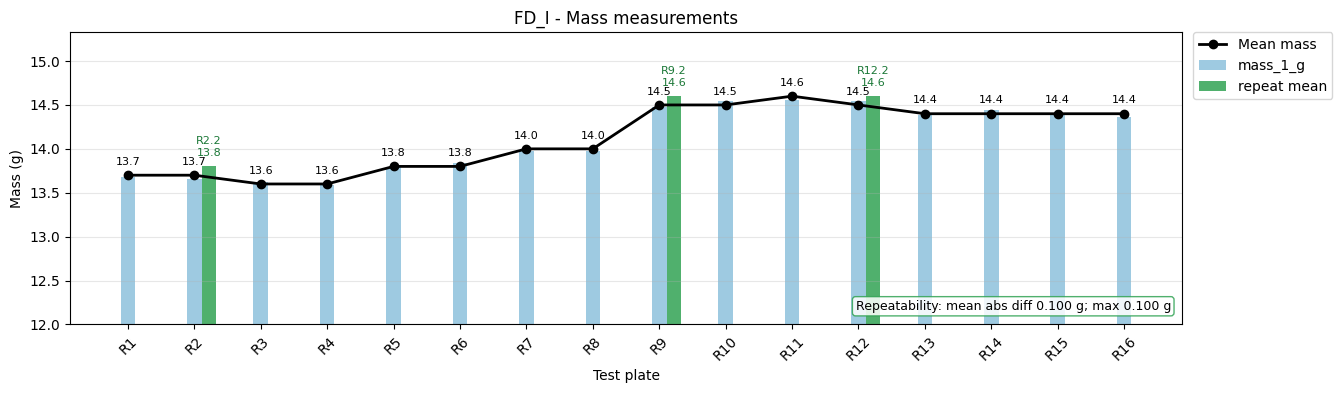

In [11]:
plot_mass_measurements(
    fd_I_mass_measurements_g,
    fd_I_mass_columns,
    y_min=12,
    mean_label="Mean mass",
    experiment="FD_I",
    repeat_measurements_g=fd_I_repeat_mass_measurements_g,
)


#### FD_I Repeatability From Repeated Prints


In [12]:
fd_I_repeatability = calculate_repeatability(
    fd_I_mass_measurements_g,
    fd_I_repeat_mass_measurements_g,
)

display(fd_I_repeatability)
print(
    "Mean absolute repeat difference:",
    f"{fd_I_repeatability['abs_difference_g'].mean():.3f} g",
)


,run_repeat,original_run,original_mass_mean_g,repeat_mass_mean_g,difference_g,abs_difference_g,difference_percent
0,R2.2,R2,13.7,13.8,0.1,0.1,0.73
1,R9.2,R9,14.5,14.6,0.1,0.1,0.69
2,R12.2,R12,14.5,14.6,0.1,0.1,0.69


Mean absolute repeat difference: 0.100 g


### FD_II Mass Measurements


In [13]:
mass_measurements_g, mass_columns = build_mass_measurements(FD_II_MASS_MEASUREMENTS_G)

display(mass_measurements_g[["run", *mass_columns, "mass_mean_g", "mass_std_g"]])


,run,mass_1_g,mass_mean_g,mass_std_g
0,RR1,84.536,84.5,NaN
1,RR2,84.550,84.6,NaN
2,RR3,84.349,84.3,NaN
3,RR4,84.496,84.5,NaN
4,RR5,85.314,85.3,NaN
5,RR6,84.483,84.5,NaN
6,RR7,85.337,85.3,NaN
7,RR8,84.320,84.3,NaN
8,RR9,88.351,88.4,NaN
9,RR10,87.760,87.8,NaN


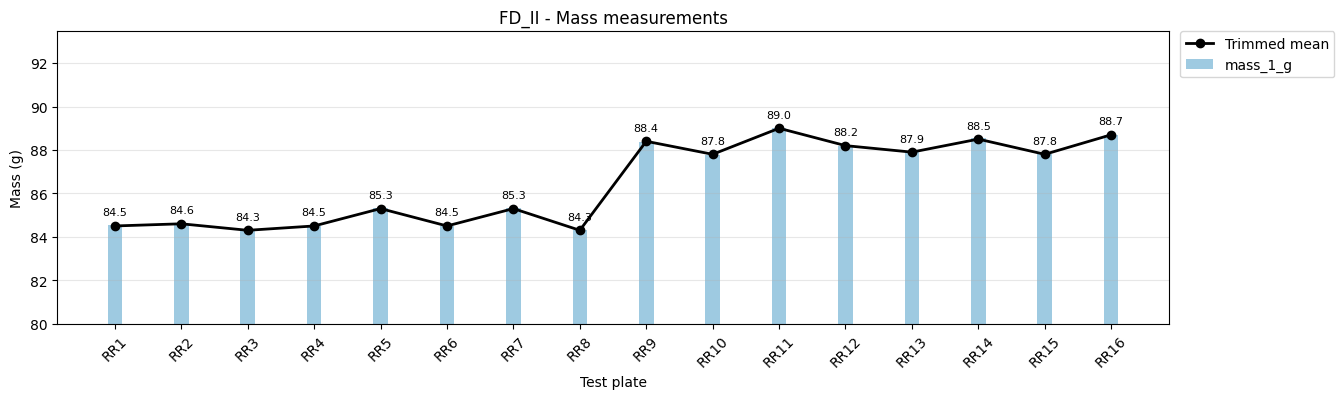

In [14]:
plot_mass_measurements(
    mass_measurements_g,
    mass_columns,
    y_min=80,
    mean_label="Trimmed mean",
    experiment="FD_II",
)


#### FD_II Repeatability Placeholder


In [15]:
# TODO: Build FD_II repeat measurements and calculate repeatability.
# fd_II_repeatability = calculate_repeatability(
#     mass_measurements_g,
#     fd_II_repeat_mass_measurements_g,
# )
# display(fd_II_repeatability)


### Extra-Run Mass Measurements


,run,mass_1_g,mass_2_g,mass_3_g,mass_4_g,mass_mean_g,mass_std_g
0,LD,35.585,35.710,NaN,None,35.6,0.088388
1,HD,NaN,NaN,NaN,None,NaN,NaN
2,E1,86.642,87.034,86.975,None,86.9,0.211358
3,E2,NaN,NaN,NaN,None,NaN,NaN
4,E3,NaN,NaN,NaN,None,NaN,NaN
5,E4,NaN,NaN,NaN,None,NaN,NaN
6,E5,NaN,NaN,NaN,None,NaN,NaN
7,E6,NaN,NaN,NaN,None,NaN,NaN


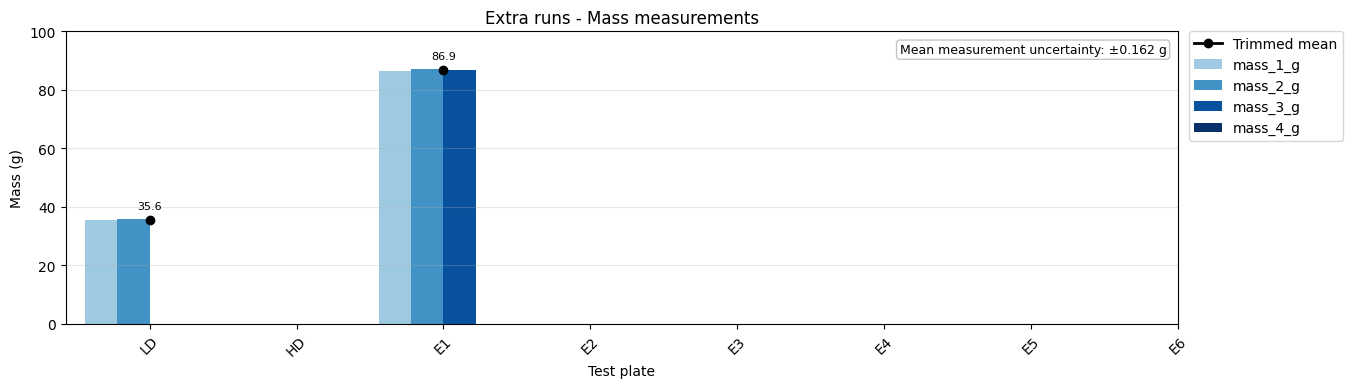

In [16]:
extra_run_mass_measurements_g, extra_run_mass_columns = build_mass_measurements(
    EXTRA_RUN_MASS_MEASUREMENTS_G,
    run_labels=EXTRA_RUN_LABELS,
)

display(extra_run_mass_measurements_g[[
    "run",
    *extra_run_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])

plot_mass_measurements(
    extra_run_mass_measurements_g,
    extra_run_mass_columns,
    y_min=0,
    y_max=100,
    mean_label="Trimmed mean",
    experiment="Extra runs",
)

### Box-Behnken Mass Measurements From New Scale


,run,mass_1_g,mass_2_g,mass_mean_g,mass_std_g
0,B1,89.090,89.100,89.1,0.007071
1,B2,89.015,89.022,89.0,0.004950
2,B3,88.986,88.996,89.0,0.007071
3,B4,89.171,89.183,89.2,0.008485
4,B5,89.313,89.316,89.3,0.002121
5,B6,89.789,89.796,89.8,0.004950
6,B7,89.720,89.730,89.7,0.007071
7,B8,89.306,89.312,89.3,0.004243
8,B9,88.868,88.863,88.9,0.003536
9,B10,89.093,89.105,89.1,0.008485


,runs_with_repeated_measurements,mean_measurement_std_g,rms_measurement_uncertainty_g,max_measurement_std_g
0,15,0.0058,0.0063,0.0092


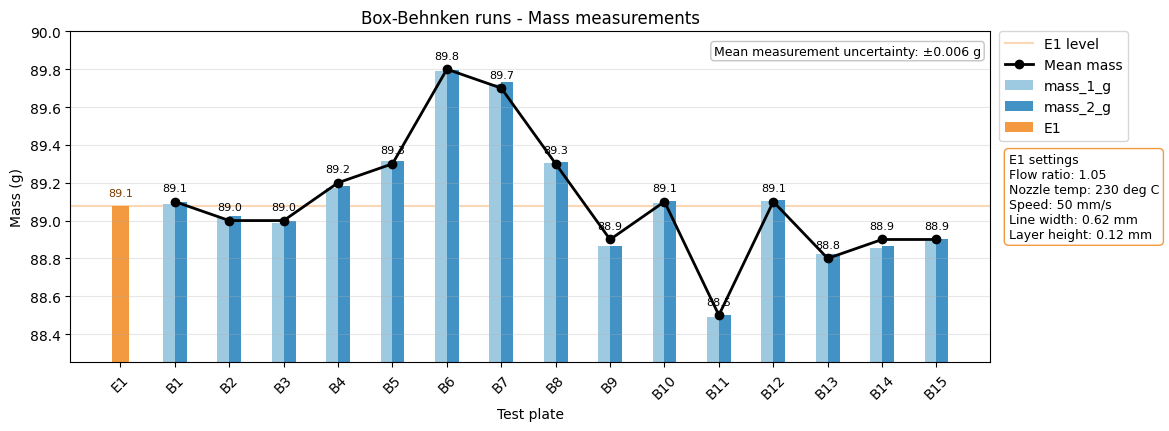

In [17]:
box_behnken_mass_measurements_g, box_behnken_mass_columns = build_mass_measurements(
    BOX_BEHNKEN_NEW_SCALE_MASS_MEASUREMENTS_G,
    run_labels=BOX_BEHNKEN_NEW_SCALE_RUN_LABELS,
)

display(box_behnken_mass_measurements_g[[
    "run",
    *box_behnken_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])

box_behnken_repeated_measurements_g = box_behnken_mass_measurements_g.dropna(
    subset=["mass_std_g"]
)
box_behnken_measurement_uncertainty_summary = pd.DataFrame([{
    "runs_with_repeated_measurements": len(box_behnken_repeated_measurements_g),
    "mean_measurement_std_g": box_behnken_repeated_measurements_g["mass_std_g"].mean(),
    "rms_measurement_uncertainty_g": (
        (box_behnken_repeated_measurements_g["mass_std_g"] ** 2).mean() ** 0.5
    ),
    "max_measurement_std_g": box_behnken_repeated_measurements_g["mass_std_g"].max(),
}])
display(box_behnken_measurement_uncertainty_summary.round(4))

e1_reference_mass_g = 89.077

plot_mass_measurements(
    box_behnken_mass_measurements_g,
    box_behnken_mass_columns,
    y_min=88.25,
    y_max=90,
    mean_label="Mean mass",
    experiment="Box-Behnken runs",
    reference_mass_g=e1_reference_mass_g,
    reference_label="E1",
    reference_details=(
        "E1 settings\n"
        "Flow ratio: 1.05\n"
        "Nozzle temp: 230 deg C\n"
        "Speed: 50 mm/s\n"
        "Line width: 0.62 mm\n"
        "Layer height: 0.12 mm"
    ),
)


### Ironing-Run Mass Measurement Placeholders


In [ ]:
ironing_mass_measurements_g, ironing_mass_columns = build_mass_measurements(
    IRONING_MASS_MEASUREMENTS_G,
    run_labels=IRONING_RUN_LABELS,
)

display(ironing_mass_measurements_g[[
    "run",
    *ironing_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])

plot_mass_measurements(
    ironing_mass_measurements_g,
    ironing_mass_columns,
    y_min=8,
    y_max=10,
    mean_label="Trimmed mean",
    experiment="Ironing runs",
)


## Step 3: Analyze Effects, Interactions, And Models


### FD_I Screening Analysis


#### FD_I Main-Effect Estimates


In [19]:
mass_result_matrix_I = build_result_matrix(
    fd_I_coded_df,
    fd_I_mass_measurements_g,
    response="mass_mean_g",
)
mass_result_matrix_I


,A_flow_ratio,B_nozzle_temp,C_speed,D_line_width,E_layer_height,F_walls,mass_mean_g
Run,,,,,,,
1,-1,-1,-1,-1,1,1,13.7
2,-1,-1,-1,1,1,1,13.7
3,-1,-1,1,-1,1,-1,13.6
4,-1,-1,1,1,1,-1,13.6
5,-1,1,-1,-1,-1,1,13.8
6,-1,1,-1,1,-1,1,13.8
7,-1,1,1,-1,-1,-1,14.0
8,-1,1,1,1,-1,-1,14.0
9,1,-1,-1,-1,-1,-1,14.5


In [20]:
main_effect_df_I = compute_main_effects(mass_result_matrix_I)
main_effect_df_I


,Effect,Main effect
0,A_flow_ratio,0.6875
1,B_nozzle_temp,0.0625
2,C_speed,0.0375
3,D_line_width,-0.0125
4,E_layer_height,-0.1875
5,F_walls,-0.0125


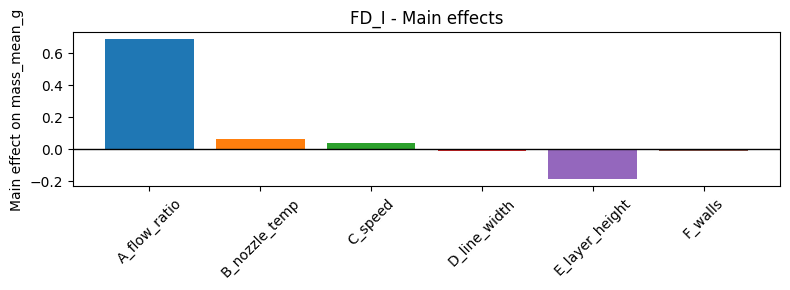

In [21]:
plot_main_effects_bar(
    main_effect_df_I,
    response="mass_mean_g",
    experiment="FD_I",
)


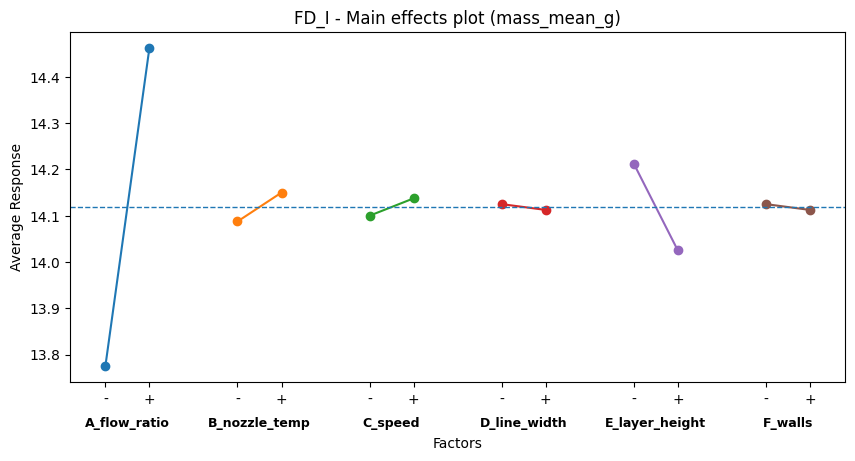

In [22]:
plot_main_effects_line(
    mass_result_matrix_I,
    response="mass_mean_g",
    experiment="FD_I",
)


#### FD_I Aliased Interaction Estimates


In [23]:
mass_interaction_matrix = add_interactions(mass_result_matrix_I)

#mass_interaction_matrix


In [24]:
FD_I_GENERATORS = {
    "E_layer_height": ("A_flow_ratio", "B_nozzle_temp"),  # E = AB
    "F_walls": ("A_flow_ratio", "C_speed"),  # F = AC
}

interaction_effects_I = compute_interaction_effects(
    mass_result_matrix_I,
    response="mass_mean_g",
    generators=FD_I_GENERATORS,
)

interaction_effects_I


,Interaction,Alias / generator note,Effect
7,B_nozzle_temp x E_layer_height,,0.6875
11,C_speed x F_walls,,0.6875
0,A_flow_ratio x B_nozzle_temp,E_layer_height; generator E=AB,-0.1875
8,B_nozzle_temp x F_walls,,-0.0875
10,C_speed x E_layer_height,,-0.0875
3,A_flow_ratio x E_layer_height,,0.0625
5,B_nozzle_temp x C_speed,,0.0625
14,E_layer_height x F_walls,,0.0625
4,A_flow_ratio x F_walls,,0.0375
2,A_flow_ratio x D_line_width,,-0.0125


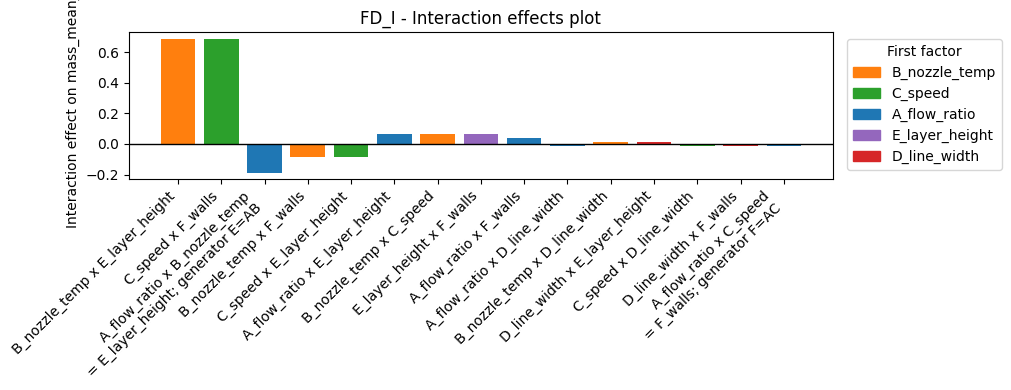

In [25]:
plot_interaction_effects(
    interaction_effects_I,
    experiment="FD_I",
)


### FD_II Screening Analysis


#### FD_II Main-Effect Estimates


In [26]:
mass_result_matrix_II = build_result_matrix(
    fd_II_coded_df,
    mass_measurements_g,
    response="mass_mean_g",
)
#mass_result_matrix_II


In [27]:
main_effect_df = compute_main_effects(mass_result_matrix_II, response="mass_mean_g")
main_effect_df


,Effect,Main effect
0,A_flow_ratio,3.625
1,B_nozzle_temp,0.125
2,C_speed,0.075
3,D_line_width,-0.175
4,E_layer_height,-0.250


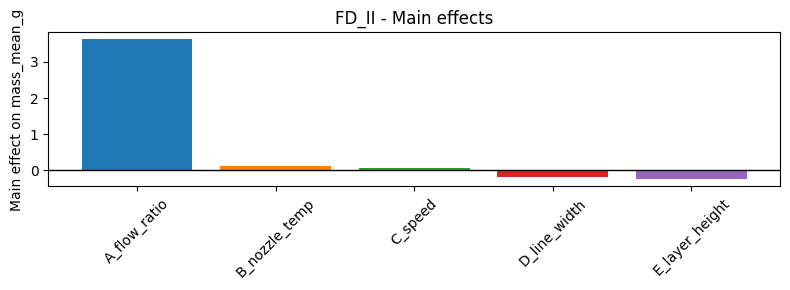

In [28]:
plot_main_effects_bar(
    main_effect_df,
    response="mass_mean_g",
    experiment="FD_II",
)


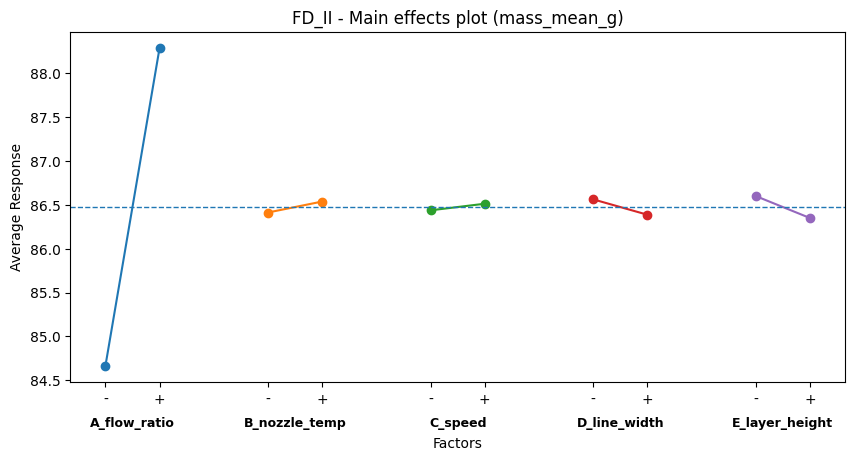

In [29]:
plot_main_effects_line(
    mass_result_matrix_II,
    response="mass_mean_g",
    experiment="FD_II",
)


#### FD_II Main-Effect Estimates Excluding Flow Ratio


In [30]:
main_effect_df_no_flow = main_effect_df[
    main_effect_df["Effect"] != "A_flow_ratio"
].copy()

mass_result_matrix_II_no_flow = mass_result_matrix_II.drop(
    columns=["A_flow_ratio"]
)

main_effect_df_no_flow


,Effect,Main effect
1,B_nozzle_temp,0.125
2,C_speed,0.075
3,D_line_width,-0.175
4,E_layer_height,-0.250


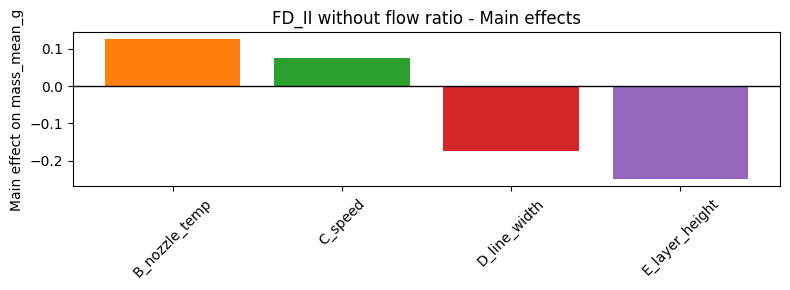

In [31]:
plot_main_effects_bar(
    main_effect_df_no_flow,
    response="mass_mean_g",
    experiment="FD_II without flow ratio",
)


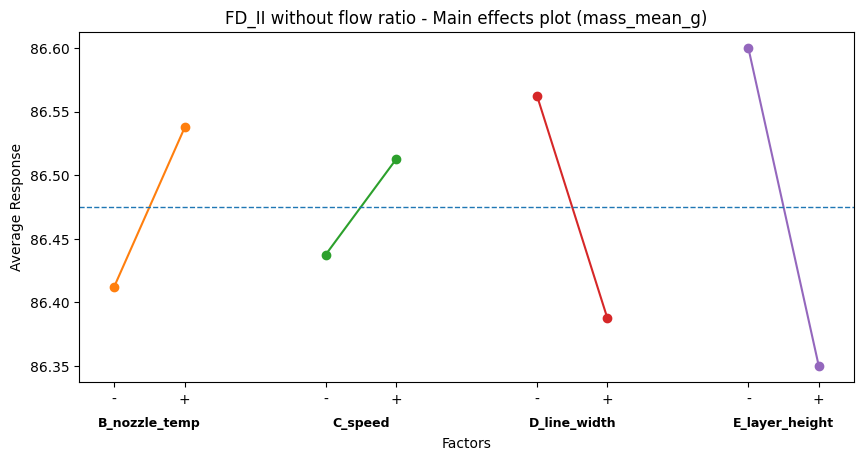

In [32]:
plot_main_effects_line(
    mass_result_matrix_II_no_flow,
    response="mass_mean_g",
    experiment="FD_II without flow ratio",
)


#### FD_II Aliased Interaction Estimates


In [33]:
FD_II_GENERATORS = {
    "E_layer_height": ("A_flow_ratio", "B_nozzle_temp"),  # E = AB
}

interaction_effects_II = compute_interaction_effects(
    mass_result_matrix_II,
    response="mass_mean_g",
    generators=FD_II_GENERATORS,
)

interaction_effects_II


,Interaction,Alias / generator note,Effect
6,B_nozzle_temp x E_layer_height,,3.625000e+00
9,D_line_width x E_layer_height,,6.250000e-01
0,A_flow_ratio x B_nozzle_temp,E_layer_height; generator E=AB,-2.500000e-01
1,A_flow_ratio x C_speed,,2.000000e-01
2,A_flow_ratio x D_line_width,,2.000000e-01
3,A_flow_ratio x E_layer_height,,1.250000e-01
8,C_speed x E_layer_height,,-1.250000e-01
4,B_nozzle_temp x C_speed,,-1.000000e-01
5,B_nozzle_temp x D_line_width,,1.000000e-01
7,C_speed x D_line_width,,1.421085e-14


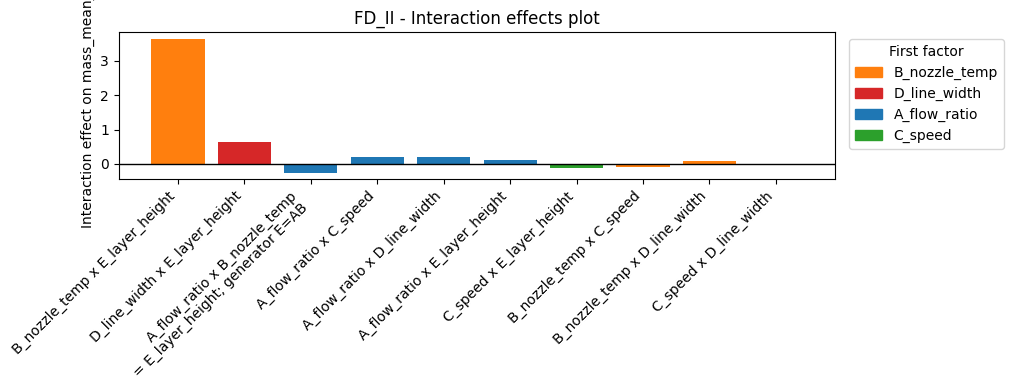

In [34]:
plot_interaction_effects(
    interaction_effects_II,
    experiment="FD_II",
)


#### FD_II Conditional Main Effects: Normal vs Overextrusion Runs


In [35]:
conditional_factor_cols = ["C_speed", "D_line_width"]

mass_result_matrix_II_RR1_8 = mass_result_matrix_II.iloc[:8][
    conditional_factor_cols + ["mass_mean_g"]
].copy()
mass_result_matrix_II_RR9_16 = mass_result_matrix_II.iloc[8:16][
    conditional_factor_cols + ["mass_mean_g"]
].copy()

conditional_effect_df_II_RR1_8 = compute_main_effects(
    mass_result_matrix_II_RR1_8,
    response="mass_mean_g",
)
conditional_effect_df_II_RR9_16 = compute_main_effects(
    mass_result_matrix_II_RR9_16,
    response="mass_mean_g",
)

display(conditional_effect_df_II_RR1_8)
display(conditional_effect_df_II_RR9_16)


,Effect,Main effect
0,C_speed,-0.125
1,D_line_width,-0.375


,Effect,Main effect
0,C_speed,0.275
1,D_line_width,0.025


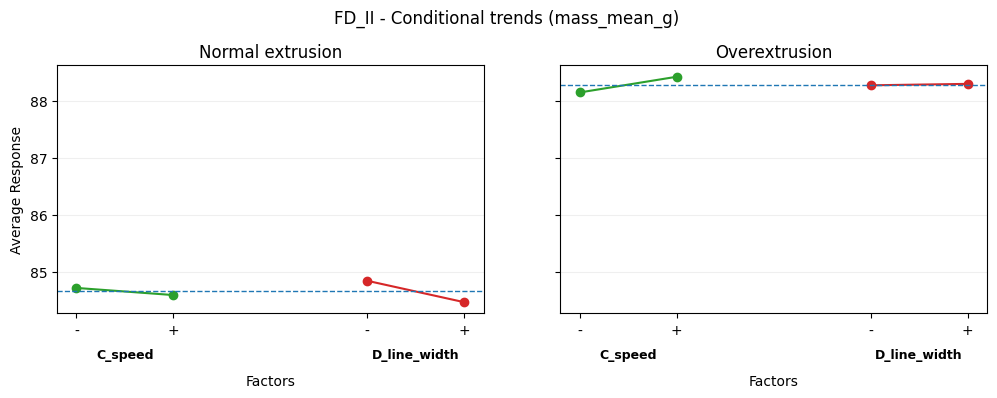

In [36]:
plot_main_effects_line_comparison(
    [mass_result_matrix_II_RR1_8, mass_result_matrix_II_RR9_16],
    labels=["Normal extrusion", "Overextrusion"],
    response="mass_mean_g",
    experiment="FD_II",
)


#### FD_II Main-Effect Prediction For E1 Confirmation Run


This comparison uses the additive main-effect model from FD_II. The prediction is calculated as `predicted mass = grand mean + sum(coded factor level * main effect / 2)`. E1 is used as the confirmation run for the main-effect maximum setting, so the predicted value comes from the FD_II screening model and the observed value comes from the measured E1 mass.


In [37]:
FD_II_FACTOR_COLUMNS = [
    "A_flow_ratio",
    "B_nozzle_temp",
    "C_speed",
    "D_line_width",
    "E_layer_height",
]

# E1 uses the best-looking FD_II settings from the main effects:
# high flow/nozzle temperature and low speed/line width/layer height.
E1_CODED_SETTING = {
    "A_flow_ratio": 1,
    "B_nozzle_temp": 1,
    "C_speed": -1,
    "D_line_width": -1,
    "E_layer_height": -1,
}

fd_II_mass_prediction_comparison = build_main_effect_prediction_comparison(
    mass_result_matrix_II,
    main_effect_df,
    FD_II_LEVELS,
    factor_cols=FD_II_FACTOR_COLUMNS,
    run_prefix="RR",
    experiment="FD_II",
    confirmation_measurements=extra_run_mass_measurements_g,
    confirmation_run="E1",
    confirmation_coded_setting=E1_CODED_SETTING,
    include_screening_rows=False,
)

display(fd_II_mass_prediction_comparison)


,case,coded_setting,real_setting,predicted_mass_g,observed_mass_g,note
0,E1 confirmation run,"{'A_flow_ratio': 1, 'B_nozzle_temp': 1, 'C_spe...","{'A_flow_ratio': 1.05, 'B_nozzle_temp': 230, '...",88.52,86.9,Predicted mass uses the FD_II main-effect maxi...


### Box-Behnken Response-Surface Analysis


The surface/contour plots visualize the fitted quadratic model. Each figure shows two factors changing across their real setting range while the third factor is held at the middle level. The 3D-style surface shows the predicted mass height; the 2D contour plot is the same surface viewed from above, where contour lines connect settings with equal predicted mass. Red points mark measured runs that lie on that slice.


The Box-Behnken analysis below uses only the new mass measurements. A quadratic response-surface model is fitted as `mass = b0 + b1*x1 + b2*x2 + b3*x3 + b11*x1^2 + b22*x2^2 + b33*x3^2 + b12*x1*x2 + b13*x1*x3 + b23*x2*x3`, where the `x` values are the coded factor levels. The center-point repeats estimate print-to-print repeatability at identical settings.


In [38]:
if "extra_run_15_coded" not in globals():
    EXTRA_RUN_BOX_BEHNKEN_LEVELS = {
        "B_nozzle_temp": {-1: 225, 0: 230, 1: 235},
        "D_line_width": {-1: 0.62, 0: 0.70, 1: 0.80},
        "E_layer_height": {-1: 0.10, 0: 0.12, 1: 0.14},
    }
    extra_run_15_coded, extra_run_15_real = create_box_behnken_design(
        EXTRA_RUN_BOX_BEHNKEN_LEVELS,
        center_repeats=3,
    )

if "box_behnken_mass_measurements_g" not in globals():
    box_behnken_mass_measurements_g, box_behnken_mass_columns = build_mass_measurements(
        BOX_BEHNKEN_NEW_SCALE_MASS_MEASUREMENTS_G,
        run_labels=BOX_BEHNKEN_NEW_SCALE_RUN_LABELS,
    )

box_behnken_result_matrix = build_result_matrix(
    extra_run_15_coded,
    box_behnken_mass_measurements_g,
    response="mass_mean_g",
)

display(box_behnken_result_matrix.dropna(subset=["mass_mean_g"]))


,B_nozzle_temp,D_line_width,E_layer_height,mass_mean_g
Run,,,,
1,0,-1,-1,89.1
2,0,-1,1,89.0
3,0,1,-1,89.0
4,0,1,1,89.2
5,-1,0,-1,89.3
6,-1,0,1,89.8
7,1,0,-1,89.7
8,1,0,1,89.3
9,-1,-1,0,88.9


,B_nozzle_temp,D_line_width,E_layer_height,run,mass_mean_g,mass_std_g,difference_from_center_mean_g,abs_difference_from_center_mean_g
Run,,,,,,,,
13,0,0,0,B13,88.8,0.000,-0.067,0.067
14,0,0,0,B14,88.9,0.006,0.033,0.033
15,0,0,0,B15,88.9,0.009,0.033,0.033


,center_repeats_with_data,center_mean_g,between_print_std_g,center_range_g,max_pair_difference_g,max_pair_difference_percent,mean_within_print_std_g
0,3,88.867,0.058,0.1,0.1,0.11,0.005


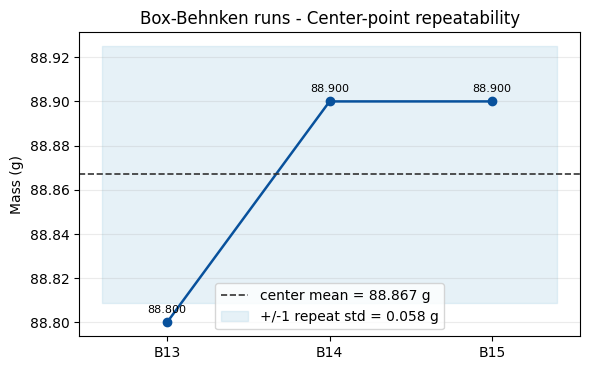

In [39]:
box_behnken_center_repeatability, box_behnken_repeatability_summary = calculate_center_point_repeatability(
    extra_run_15_coded,
    box_behnken_mass_measurements_g,
    response="mass_mean_g",
)

display(box_behnken_center_repeatability)
display(box_behnken_repeatability_summary)

plot_center_point_repeatability(
    box_behnken_center_repeatability,
    box_behnken_repeatability_summary,
    response="mass_mean_g",
    experiment="Box-Behnken runs",
)


The ANOVA table separates the variation explained by the quadratic Box-Behnken model from the unexplained residual variation. The Pareto plot ranks the fitted linear, quadratic, and interaction terms by their absolute standardized effect, so longer bars indicate terms that are more influential relative to the residual scatter.


In [40]:
box_behnken_mass_model = fit_quadratic_response_surface(
    box_behnken_result_matrix,
    response="mass_mean_g",
)

display(box_behnken_mass_model["info_df"].round(4))
display(box_behnken_mass_model["coefficient_df"].round(4))
display(box_behnken_mass_model["fitted_df"].round(3))

box_behnken_anova_table = build_quadratic_anova_table(box_behnken_mass_model)
display(box_behnken_anova_table.round(4))
display(box_behnken_mass_model["term_statistics_df"].round(4))


,measured_runs,model_terms,rank,residual_df,r_squared,residual_std
0,15,10,10,5,0.9482,0.1258


,term,coefficient
0,Intercept,88.8667
1,B_nozzle_temp,-0.0625
2,D_line_width,0.1125
3,E_layer_height,0.0250
4,B_nozzle_temp^2,0.2417
5,D_line_width^2,-0.2083
6,E_layer_height^2,0.4167
7,B_nozzle_temp:D_line_width,0.1000
8,B_nozzle_temp:E_layer_height,-0.2250
9,D_line_width:E_layer_height,0.0750


,run,B_nozzle_temp,D_line_width,E_layer_height,mass_mean_g,predicted_response,residual
Run,,,,,,,
1,1,0,-1,-1,89.1,89.012,0.088
2,2,0,-1,1,89.0,88.912,0.088
3,3,0,1,-1,89.0,89.087,-0.087
4,4,0,1,1,89.2,89.288,-0.087
5,5,-1,0,-1,89.3,89.337,-0.037
6,6,-1,0,1,89.8,89.838,-0.038
7,7,1,0,-1,89.7,89.662,0.038
8,8,1,0,1,89.3,89.262,0.038
9,9,-1,-1,0,88.9,88.950,-0.050


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,9,1.4502,0.1611,10.1766,0.01
1,Residual,5,0.0792,0.0158,NaN,NaN
2,Total,14,1.5293,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,absolute_t_value,F_value,p_value
0,Intercept,88.8667,0.0726,1223.2447,1223.2447,1.496328e+06,0.0000
1,B_nozzle_temp,-0.0625,0.0445,-1.4049,1.4049,1.973700e+00,0.2190
2,D_line_width,0.1125,0.0445,2.5288,2.5288,6.394700e+00,0.0526
3,E_layer_height,0.0250,0.0445,0.5620,0.5620,3.158000e-01,0.5984
4,B_nozzle_temp^2,0.2417,0.0655,3.6905,3.6905,1.361940e+01,0.0141
5,D_line_width^2,-0.2083,0.0655,-3.1814,3.1814,1.012150e+01,0.0245
6,E_layer_height^2,0.4167,0.0655,6.3628,6.3628,4.048580e+01,0.0014
7,B_nozzle_temp:D_line_width,0.1000,0.0629,1.5894,1.5894,2.526300e+00,0.1728
8,B_nozzle_temp:E_layer_height,-0.2250,0.0629,-3.5762,3.5762,1.278950e+01,0.0159
9,D_line_width:E_layer_height,0.0750,0.0629,1.1921,1.1921,1.421100e+00,0.2867


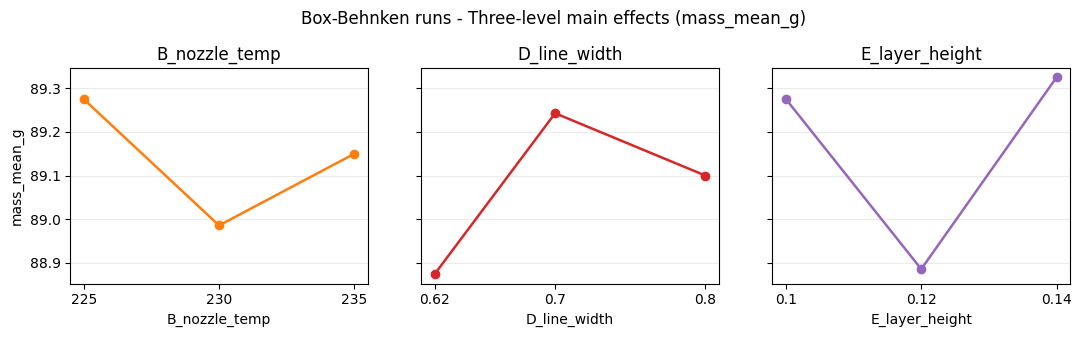

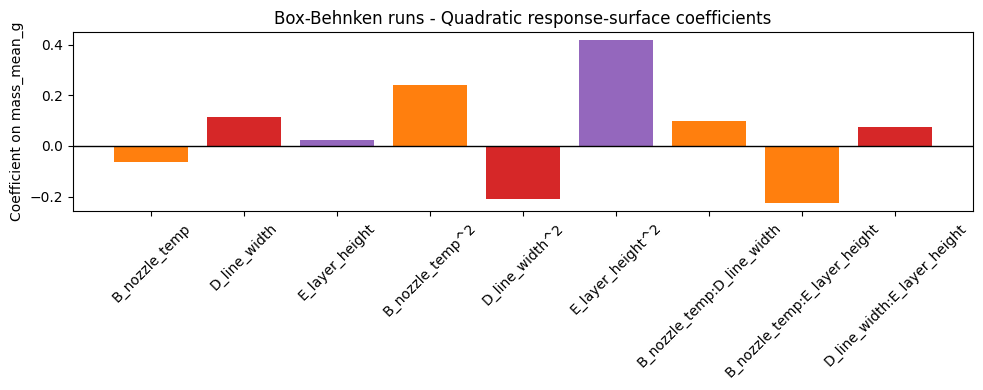

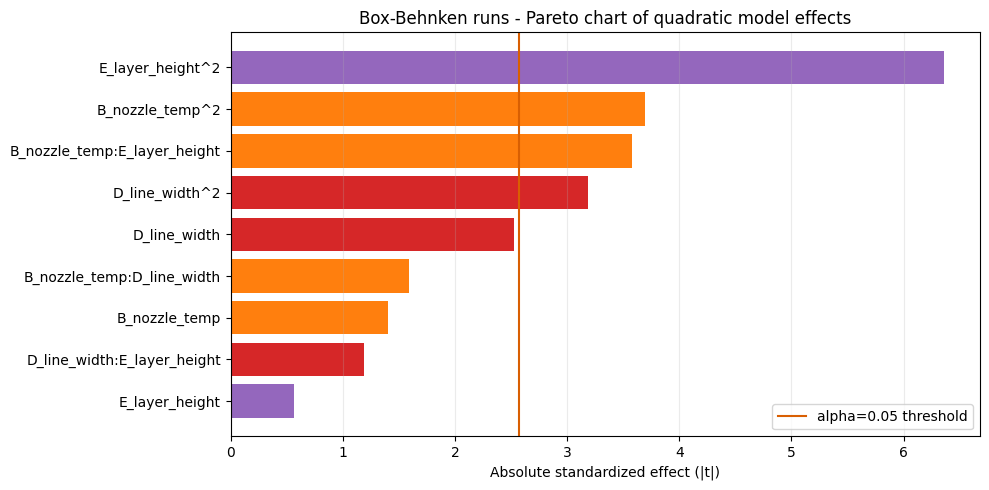

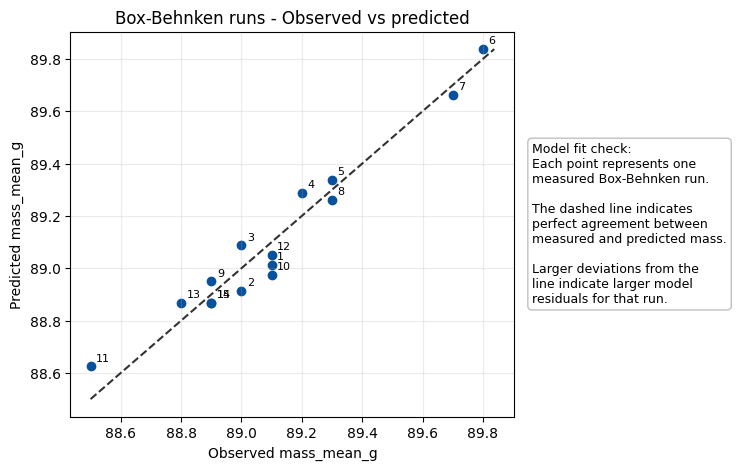

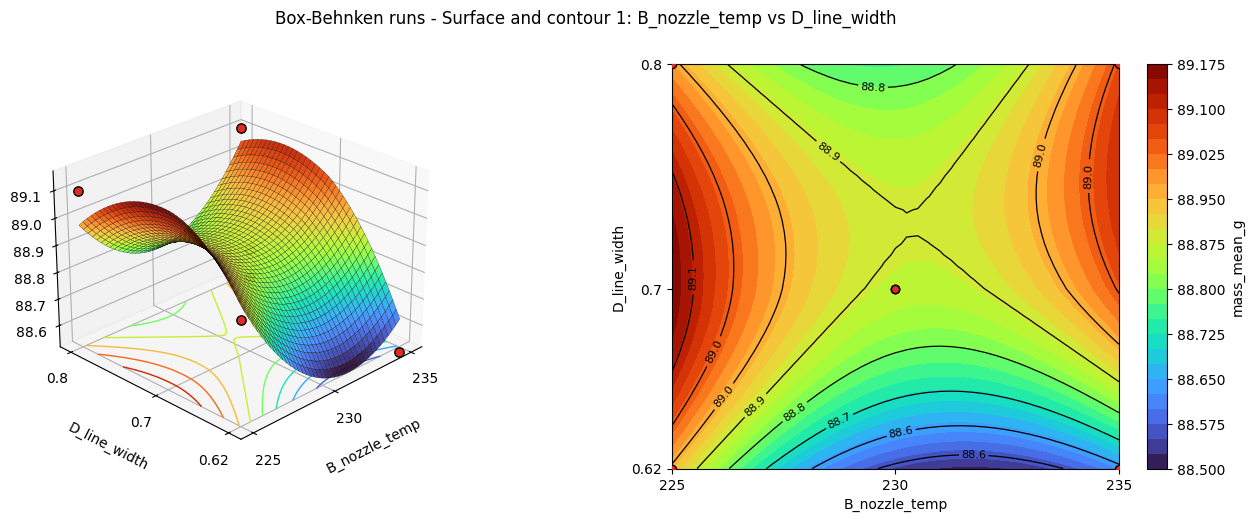

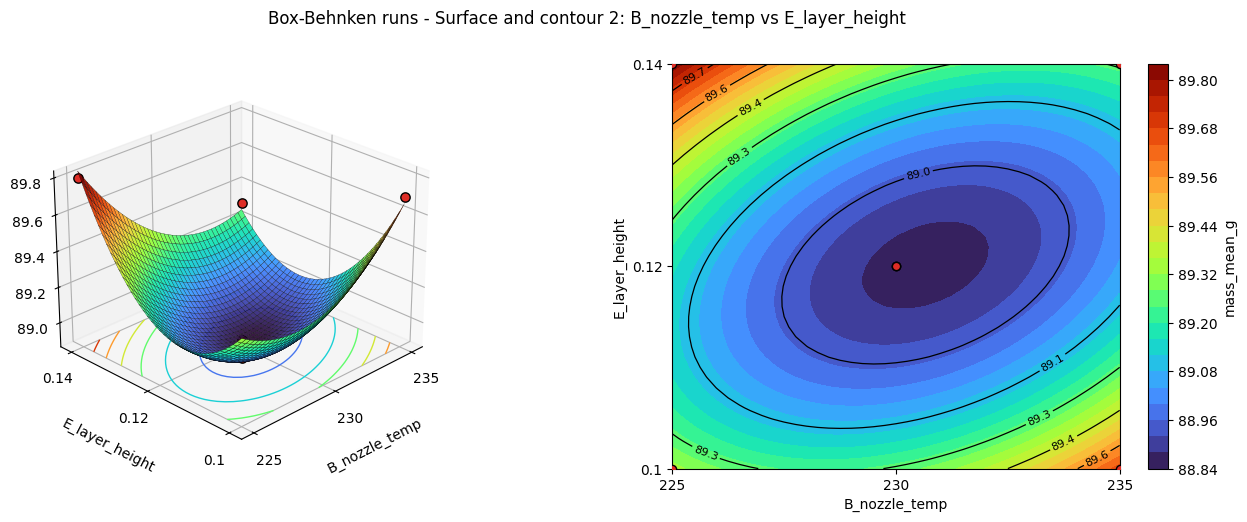

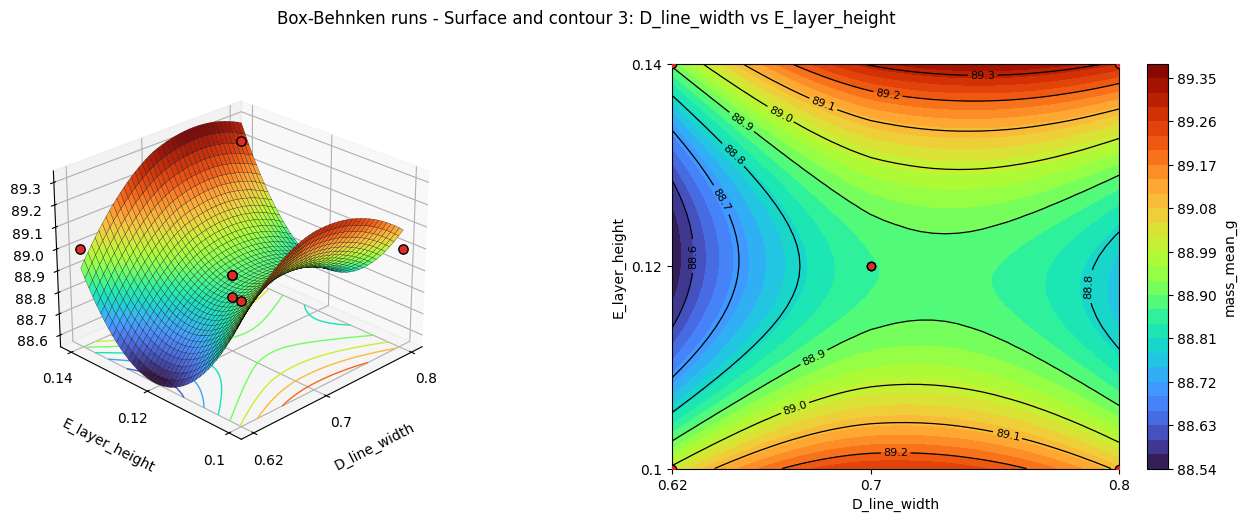

In [41]:
plot_three_level_main_effects(
    box_behnken_result_matrix,
    response="mass_mean_g",
    levels=EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    experiment="Box-Behnken runs",
)

plot_quadratic_coefficients(
    box_behnken_mass_model,
    experiment="Box-Behnken runs",
)

plot_quadratic_pareto(
    box_behnken_mass_model,
    experiment="Box-Behnken runs",
)

plot_quadratic_observed_vs_predicted(
    box_behnken_mass_model,
    experiment="Box-Behnken runs",
)

plot_quadratic_surface_and_contour_pairs(
    box_behnken_mass_model,
    levels=EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    fixed_level=0,
    experiment="Box-Behnken runs",
)
